# 03 — Neural Networks from Scratch
**A math-first, practical introduction using NumPy**

This notebook builds a small neural network without a deep-learning framework for the core calculations. The purpose is to make the internal steps visible before moving to PyTorch.

We will cover neurons, activation functions, dense layers, forward propagation, binary cross-entropy, backpropagation, gradient descent, evaluation, and a gradient check.

**Prerequisites:** Python, NumPy, Matplotlib, and the mathematical foundations from Notebook 02.

## 1. Learning objectives

By the end, you should be able to:
- Explain weights, biases, and activation functions.
- Implement forward propagation with matrix operations.
- Explain how backpropagation uses the chain rule.
- Train and evaluate a small binary classifier.
- Debug shapes and verify gradients numerically.

## 2. Setup

If necessary, install dependencies with `%pip install numpy matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Fix the seed so results are reproducible.
np.random.seed(42)
print("NumPy:", np.__version__)

NumPy: 2.4.6


## 3. A single artificial neuron

A neuron first computes a weighted sum plus a bias:

$$
z = \sum_{j=1}^{n} w_j x_j + b = \mathbf{w}^{T}\mathbf{x} + b
$$

Then it applies an activation function:

$$
a = \phi(z)
$$

Here, $(x_j)$ is an input feature, $(w_j)$ is its weight, $(b)$ is the bias, and $(\phi$) is the activation function.

In [2]:
# Define three input features, their weights, and a bias.
x = np.array([0.7, -1.2, 0.3])
w = np.array([0.5, -0.4, 0.8])
b = 0.1

# Calculate the neuron's weighted sum and sigmoid output.
z = np.dot(w, x) + b
a = 1 / (1 + np.exp(-z))

print(f"Weighted sum z: {z:.3f}")
print(f"Neuron output a: {a:.3f}")

Weighted sum z: 1.170
Neuron output a: 0.763


## 4. Activation functions

Sigmoid maps values to \((0,1)\), ReLU clips negative values to zero, and tanh maps values to \((-1,1)\).

$$
\sigma(z) = \frac{1}{1+e^{-z}}, \qquad
\operatorname{ReLU}(z)=\max(0,z)
$$

$$
\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}
$$

Sigmoid is commonly used at a binary-classification output; ReLU is a common hidden-layer activation. The right choice depends on the task.

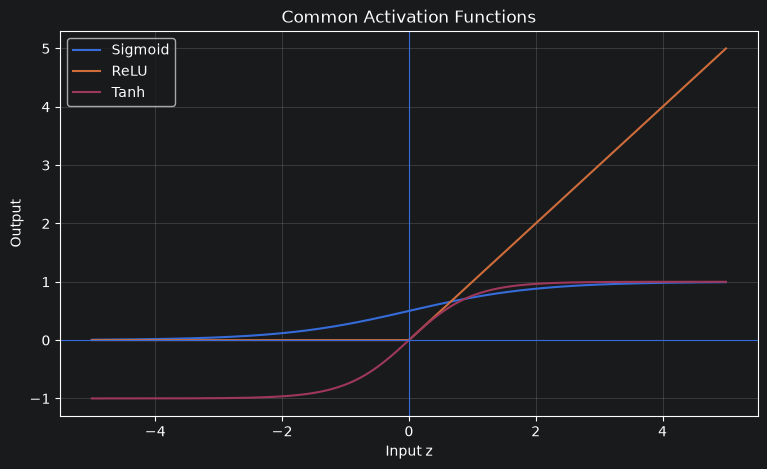

In [3]:
# Implement the activation functions.
def sigmoid(z):
    # Clip inputs to avoid overflow in exp for extreme values.
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def relu(z):
    # Return zero for negative values and z for positive values.
    return np.maximum(0, z)

def tanh(z):
    # NumPy provides a numerically stable tanh implementation.
    return np.tanh(z)

# Plot all three functions over the same input range.
z_values = np.linspace(-5, 5, 300)
plt.figure(figsize=(9, 5))
plt.plot(z_values, sigmoid(z_values), label="Sigmoid")
plt.plot(z_values, relu(z_values), label="ReLU")
plt.plot(z_values, tanh(z_values), label="Tanh")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.title("Common Activation Functions")
plt.xlabel("Input z")
plt.ylabel("Output")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. From a neuron to a dense layer

For $m$ examples and $n_{\text{in}}$ input features, arrange the inputs in a matrix $X$. A dense layer with $n_{\text{out}}$ neurons computes:

$$
Z = XW + b
$$

Shapes:

- $X: (m, n_{\text{in}})$
- $W: (n_{\text{in}}, n_{\text{out}})$
- $b: (n_{\text{out}},)$
- $Z: (m, n_{\text{out}})$

The bias is broadcast across rows. Check shapes carefully whenever you use matrix multiplication.

In [4]:
# Four examples, each with three input features.
X_demo = np.array([
    [0.2, 0.1, 0.7],
    [0.9, 0.3, 0.4],
    [0.1, 0.8, 0.2],
    [0.6, 0.5, 0.9],
])

# Define a dense layer with five output neurons.
W_demo = np.random.randn(3, 5) * 0.1
b_demo = np.zeros(5)

# Compute the linear transformation for the whole batch.
Z_demo = X_demo @ W_demo + b_demo
print("X:", X_demo.shape, "W:", W_demo.shape, "b:", b_demo.shape, "Z:", Z_demo.shape)

X: (4, 3) W: (3, 5) b: (5,) Z: (4, 5)


## 6. Build a two-layer neural network

Our network has two input features, eight hidden neurons, and one output neuron.

$$
Z_1 = XW_1 + b_1,\quad A_1 = \operatorname{ReLU}(Z_1)
$$

$$
Z_2 = A_1W_2 + b_2,\quad \hat{y} = \sigma(Z_2)
$$

The output $\hat{y}$ is a predicted probability for class 1. We cache intermediate values during the forward pass because backpropagation needs them later.

In [5]:
def initialize_parameters(n_inputs, n_hidden, n_outputs=1):
    # He-style initialization helps set a useful scale for ReLU layers.
    W1 = np.random.randn(n_inputs, n_hidden) * np.sqrt(2.0 / n_inputs)
    b1 = np.zeros((1, n_hidden))
    W2 = np.random.randn(n_hidden, n_outputs) * np.sqrt(1.0 / n_hidden)
    b2 = np.zeros((1, n_outputs))
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

def forward_pass(X, params):
    # Hidden layer: linear transformation followed by ReLU.
    Z1 = X @ params["W1"] + params["b1"]
    A1 = relu(Z1)
    # Output layer: linear transformation followed by sigmoid.
    Z2 = A1 @ params["W2"] + params["b2"]
    y_hat = sigmoid(Z2)
    # Save values required by the backward pass.
    cache = {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "y_hat": y_hat}
    return y_hat, cache

# Run a forward pass with sample inputs.
params_demo = initialize_parameters(2, 8)
pred_demo, cache_demo = forward_pass(np.array([[0.2, 0.8], [0.9, 0.1]]), params_demo)
print("Prediction shape:", pred_demo.shape)
print(pred_demo)

Prediction shape: (2, 1)
[[0.48388088]
 [0.49569412]]


## 7. Create a synthetic binary-classification dataset

We create two-dimensional points. Class 1 is assigned when both features have the same sign; class 0 otherwise. A small amount of label noise makes the task less perfectly separable.

This is a teaching example, not biological or clinical data.

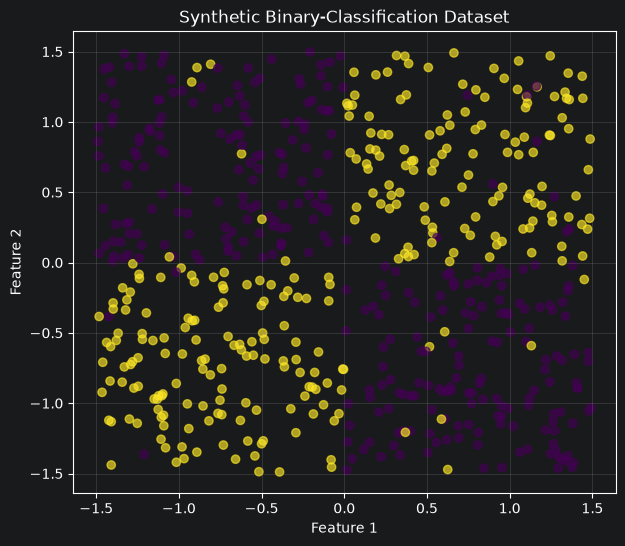

In [6]:
# Generate reproducible points in a square.
rng = np.random.default_rng(7)
n_samples = 600
X_data = rng.uniform(-1.5, 1.5, size=(n_samples, 2))

# Create labels from the signs of the two features.
y_data = ((X_data[:, 0] * X_data[:, 1]) > 0).astype(float).reshape(-1, 1)

# Flip 5% of labels to introduce noise.
flip_mask = rng.random((n_samples, 1)) < 0.05
y_data = np.where(flip_mask, 1.0 - y_data, y_data)

# Visualize the dataset.
plt.figure(figsize=(7, 6))
plt.scatter(X_data[:, 0], X_data[:, 1], c=y_data.ravel(), alpha=0.65)
plt.title("Synthetic Binary-Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, alpha=0.25)
plt.show()

## 8. Split training and test data

The training set is used to update parameters. The test set is held aside to estimate performance on unseen examples. In larger projects, a validation set is also used for model selection.

In [7]:
# Shuffle indices and split 80% for training and 20% for testing.
indices = rng.permutation(len(X_data))
split_at = int(0.8 * len(indices))
train_idx, test_idx = indices[:split_at], indices[split_at:]

X_train, y_train = X_data[train_idx], y_data[train_idx]
X_test, y_test = X_data[test_idx], y_data[test_idx]

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (480, 2) (480, 1)
Testing: (120, 2) (120, 1)


## 9. Binary cross-entropy loss

For binary classification, binary cross-entropy measures the mismatch between true labels and predicted probabilities:

$$
L = -\frac{1}{m}\sum_{i=1}^{m}
\left[
y_i\log(\hat{y}_i)+(1-y_i)\log(1-\hat{y}_i)
\right]
$$

It penalizes confident predictions that are wrong. We clip probabilities slightly away from 0 and 1 to avoid $\log(0)$.

In [8]:
def binary_cross_entropy(y_true, y_hat):
    # Keep probabilities away from exactly zero and one for stable logs.
    eps = 1e-12
    p = np.clip(y_hat, eps, 1.0 - eps)
    # Average the negative log-likelihood over all examples.
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

# Check the loss on two simple predictions.
print("Example BCE:", binary_cross_entropy(
    np.array([[1.0], [0.0]]),
    np.array([[0.9], [0.2]])
))

Example BCE: 0.164252033486018


## 10. Backpropagation

Backpropagation uses the chain rule to compute how the loss changes with each parameter.

For sigmoid output with binary cross-entropy:

$$
dZ_2 = \frac{\partial L}{\partial Z_2} = \frac{\hat{y}-y}{m}
$$

$$
dW_2 = A_1^T dZ_2,\qquad db_2 = \sum_i dZ_{2,i}
$$

$$
dA_1 = dZ_2 W_2^T,\qquad
dZ_1 = dA_1 \odot \mathbb{1}(Z_1 > 0)
$$

$$
dW_1 = X^T dZ_1,\qquad db_1 = \sum_i dZ_{1,i}
$$

The symbol $\odot$ denotes element-wise multiplication. The gradients are calculated first; parameters are updated afterward.

In [9]:
def backward_pass(y_true, params, cache):
    # Unpack values stored during the forward pass.
    X, Z1, A1, y_hat = cache["X"], cache["Z1"], cache["A1"], cache["y_hat"]
    m = X.shape[0]

    # Gradient of BCE with sigmoid output.
    dZ2 = (y_hat - y_true) / m
    # Gradients for output-layer parameters.
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Propagate the gradient into the hidden layer.
    dA1 = dZ2 @ params["W2"].T
    # ReLU derivative is one for positive pre-activations and zero otherwise.
    dZ1 = dA1 * (Z1 > 0)
    # Gradients for hidden-layer parameters.
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}

# Inspect gradient shapes on a small batch.
params_check = initialize_parameters(2, 8)
pred_check, cache_check = forward_pass(X_train[:16], params_check)
grads_check = backward_pass(y_train[:16], params_check, cache_check)
for name, grad in grads_check.items():
    print(name, grad.shape)

dW1 (2, 8)
db1 (1, 8)
dW2 (8, 1)
db2 (1, 1)


## 11. Gradient descent

Gradient descent updates parameters opposite to the gradient:

$$
\theta_{\text{new}} = \theta_{\text{old}} - \eta \nabla_\theta L
$$

Here $\eta$ is the learning rate. A value that is too small can make training slow; a value that is too large can overshoot useful parameter values or cause unstable optimization.

In [10]:
def update_parameters(params, grads, learning_rate):
    # Move each parameter opposite its gradient.
    for parameter_name in ("W1", "b1", "W2", "b2"):
        gradient_name = "d" + parameter_name
        params[parameter_name] -= learning_rate * grads[gradient_name]
    return params

## 12. Train the network

Each epoch performs a forward pass, calculates loss, backpropagates gradients, and updates parameters. We use full-batch gradient descent so the process is easy to follow. Mini-batch training will be covered in a later notebook.

In [11]:
# Initialize a fresh model before training.
params = initialize_parameters(n_inputs=2, n_hidden=8)
learning_rate = 0.5
epochs = 3000
loss_history = []

for epoch in range(epochs):
    # 1. Calculate predictions and cache intermediate values.
    y_hat_train, cache = forward_pass(X_train, params)
    # 2. Measure the current prediction error.
    loss = binary_cross_entropy(y_train, y_hat_train)
    loss_history.append(loss)
    # 3. Calculate gradients with backpropagation.
    grads = backward_pass(y_train, params, cache)
    # 4. Update all weights and biases.
    params = update_parameters(params, grads, learning_rate)

    # Print periodic progress so training can be monitored.
    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | loss = {loss:.4f}")

print(f"Final recorded loss: {loss_history[-1]:.4f}")

Epoch    0 | loss = 0.7386
Epoch  500 | loss = 0.2881
Epoch 1000 | loss = 0.2797
Epoch 1500 | loss = 0.2769
Epoch 2000 | loss = 0.2763
Epoch 2500 | loss = 0.2761
Final recorded loss: 0.2760


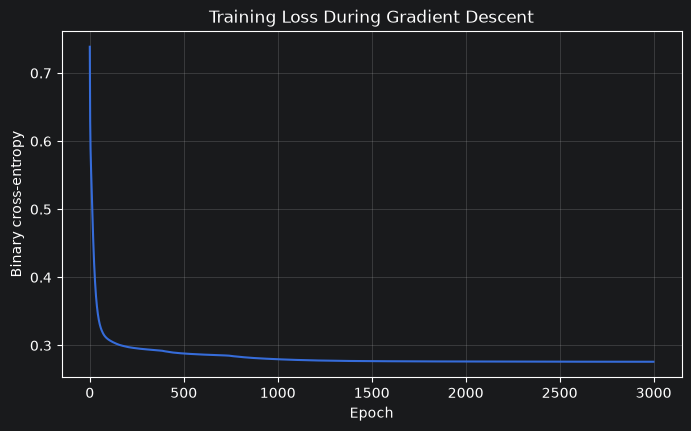

In [12]:
# Plot the loss curve to check whether optimization made progress.
plt.figure(figsize=(8, 4.5))
plt.plot(loss_history)
plt.title("Training Loss During Gradient Descent")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.grid(True, alpha=0.3)
plt.show()

## 13. Evaluate on held-out data

A sigmoid output is converted to a predicted class using a threshold of 0.5:

\[
\hat{c} =
\begin{cases}
1 & \text{if } \hat{y} \geq 0.5 \\
0 & \text{otherwise}
\end{cases}
\]

We report test loss and accuracy. Accuracy alone is not enough for every application, especially with imbalanced classes or different costs for false positives and false negatives.

In [13]:
# Predict on test examples that were not used for parameter updates.
y_hat_test, _ = forward_pass(X_test, params)
y_pred_test = (y_hat_test >= 0.5).astype(int)

# Calculate test loss and classification accuracy.
test_loss = binary_cross_entropy(y_test, y_hat_test)
test_accuracy = np.mean(y_pred_test == y_test.astype(int))
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.2200
Test accuracy: 95.00%


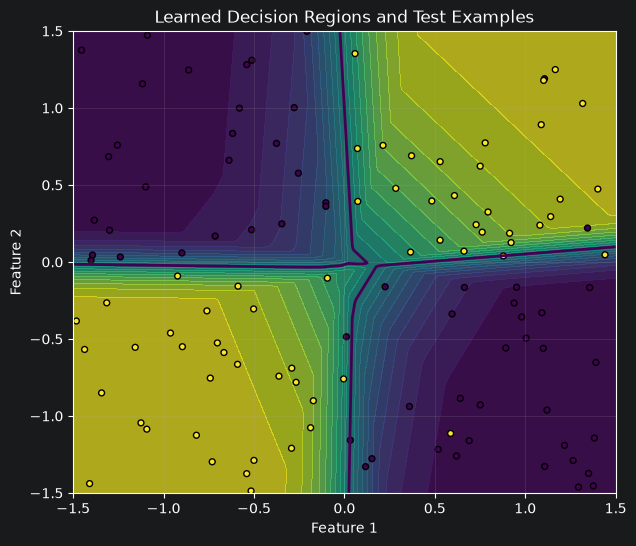

In [14]:
# Plot predicted probabilities over a grid to visualize the decision regions.
grid_x, grid_y = np.meshgrid(
    np.linspace(-1.5, 1.5, 250),
    np.linspace(-1.5, 1.5, 250),
)
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
grid_probs, _ = forward_pass(grid_points, params)
grid_probs = grid_probs.reshape(grid_x.shape)

plt.figure(figsize=(7, 6))
plt.contourf(grid_x, grid_y, grid_probs, levels=20, alpha=0.7)
plt.contour(grid_x, grid_y, grid_probs, levels=[0.5], linewidths=2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(), edgecolors="black", s=18)
plt.title("Learned Decision Regions and Test Examples")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, alpha=0.2)
plt.show()

## 14. Finite-difference gradient check

Backpropagation code can contain subtle mistakes. For a parameter $w$, a numerical approximation to its derivative is:

$$
\frac{\partial L}{\partial w}
\approx
\frac{L(w+\varepsilon)-L(w-\varepsilon)}{2\varepsilon}
$$

This is expensive for large models, but useful for checking gradients in small examples.

In [16]:
def loss_for_parameters(X, y, candidate_params):
    # Evaluate the loss without modifying the candidate parameters.
    predictions, _ = forward_pass(X, candidate_params)
    return binary_cross_entropy(y, predictions)

# Use a small subset and a fresh, small network for the check.
X_tiny, y_tiny = X_train[:12], y_train[:12]
params_tiny = initialize_parameters(2, 4)
pred_tiny, cache_tiny = forward_pass(X_tiny, params_tiny)
grads_tiny = backward_pass(y_tiny, params_tiny, cache_tiny)
analytical = grads_tiny["dW1"][0, 0]

# Make independent copies and perturb one weight in both directions.
epsilon = 1e-5
params_plus = {k: v.copy() for k, v in params_tiny.items()}
params_minus = {k: v.copy() for k, v in params_tiny.items()}
params_plus["W1"][0, 0] += epsilon
params_minus["W1"][0, 0] -= epsilon

loss_plus = loss_for_parameters(X_tiny, y_tiny, params_plus)
loss_minus = loss_for_parameters(X_tiny, y_tiny, params_minus)
numerical = (loss_plus - loss_minus) / (2 * epsilon)

print(f"Analytical gradient: {analytical:.8f}")
print(f"Numerical gradient:  {numerical:.8f}")
print(f"Absolute difference: {abs(analytical - numerical):.2e}")

Analytical gradient: 0.01588096
Numerical gradient:  0.01588096
Absolute difference: 2.40e-12


## 15. How this connects to PyTorch

The NumPy implementation made the forward pass, gradients, and updates explicit. PyTorch automates gradient calculation with **autograd**, but the underlying calculus is the same.

In [17]:
import torch

# Create a scalar tensor and ask autograd to track its gradient.
w_torch = torch.tensor(2.0, requires_grad=True)

# Define a simple differentiable loss.
loss_torch = (w_torch - 5.0) ** 2

# Compute d(loss)/d(w) using automatic differentiation.
loss_torch.backward()

print("Loss:", loss_torch.item())
print("Gradient:", w_torch.grad.item())  # 2 * (2 - 5) = -6

Loss: 9.0
Gradient: -6.0


## 16. Common mistakes

- **Wrong shapes:** inspect `.shape` before matrix multiplication.
- **Missing bias:** a dense layer computes $XW+b$.
- **No nonlinear activation:** stacked linear layers are still equivalent to one linear transformation.
- **Wrong update sign:** gradient descent subtracts the gradient.
- **Unstable logarithms:** avoid $\log(0)$ by clipping probabilities.
- **Data leakage:** never use test labels to update parameters.
- **Over-relying on accuracy:** use precision, recall, F1, ROC-AUC, and class balance where appropriate.
- **Training loss only:** a low training loss does not guarantee generalization.

## 17. Exercises

1. Change the single neuron's input, weights, and bias. Predict the direction of the output change before running the cell.
2. Compare networks with 2, 8, and 32 hidden neurons.
3. Try learning rates `0.05`, `0.5`, and `1.5`. Which are stable in your run?
4. Repeat the finite-difference gradient check for a `W2` weight or a bias.
5. Add precision and recall to the test evaluation. Why might accuracy hide poor performance on a minority class?
6. Modify the training loop to use mini-batches instead of the full training set.

**Challenge:** make the synthetic task harder and investigate how model size and learning rate affect generalization. Keep the test set separate from all parameter updates.

## 18. Quick reference

| Concept | Formula / meaning |
|---|---|
| Neuron pre-activation | \(z=\mathbf{w}^T\mathbf{x}+b\) |
| Dense layer | \(Z=XW+b\) |
| Sigmoid | \(\sigma(z)=1/(1+e^{-z})\) |
| ReLU | \(\max(0,z)\) |
| Binary cross-entropy | Mean negative log-likelihood for binary labels |
| Forward propagation | Calculate predictions from inputs and parameters |
| Backpropagation | Apply the chain rule to calculate parameter gradients |
| Gradient descent | \(\theta\leftarrow\theta-\eta\nabla_\theta L\) |
| Generalization | Performance on examples not used for parameter updates |

### Functions implemented

- `sigmoid(z)`, `relu(z)`, `tanh(z)`
- `initialize_parameters(...)`
- `forward_pass(X, params)`
- `binary_cross_entropy(y_true, y_hat)`
- `backward_pass(y_true, params, cache)`
- `update_parameters(params, grads, learning_rate)`